# QBUS3340 Task 4: ML demand prediction (ZORA, synthetic data)



In [22]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error

XLSX = "ZORA_synthetic_demand_data.xlsx"
Y = "synthetic_demand_preforms"
SEED = 3340
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

hist = pd.read_excel(XLSX, sheet_name="Historical_Demand")
conf = pd.read_excel(XLSX, sheet_name="Confirmed_20_Day_Demand")
print(hist.shape, hist.date.min().date(), "to", hist.date.max().date(),
      "| missing values:", int(hist.isna().sum().sum()))
hist.head()

(398, 9) 2025-07-01 to 2026-08-02 | missing values: 0


,date,day_index,day_of_week,week_of_year,month,is_weekend,large_customer_project,quote_request_index,synthetic_demand_preforms
0,2025-07-01,1,Tue,27,7,0,0,54,46
1,2025-07-02,2,Wed,27,7,0,0,49,43
2,2025-07-03,3,Thu,27,7,0,0,52,42
3,2025-07-04,4,Fri,27,7,0,0,60,43
4,2025-07-05,5,Sat,27,7,1,0,52,26


## Quick look at the data

Weekday, large-project windows and the quote index all move demand, and demand is strongly autocorrelated. These drive the feature choice below.

In [23]:
print(hist.groupby("day_of_week")[Y].mean()
      .reindex(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]).round(1).to_string())
print()
print(hist.groupby("large_customer_project")[Y].agg(["mean", "count"]).round(1).to_string())
print()
print("corr(demand, quote_request_index):", round(hist[Y].corr(hist["quote_request_index"]), 3))
print("autocorrelation lag1 / lag7:", round(hist[Y].autocorr(1), 3), "/", round(hist[Y].autocorr(7), 3))

day_of_week
Mon    55.5
Tue    54.0
Wed    51.1
Thu    50.6
Fri    47.9
Sat    44.8
Sun    44.1

                        mean  count
large_customer_project             
0                       47.0    329
1                       62.4     69

corr(demand, quote_request_index): 0.537
autocorrelation lag1 / lag7: 0.635 / 0.606


## 4.a Features and chronological split

Features for day *t*: lag-1, lag-2, lag-7 demand, the mean of the previous 7 days, day-of-week dummies (Monday is the reference), the large-project flag, and the quote index for days *t* and *t-1*. Month dummies are left out because one year of data cannot separate seasonality from level shifts.

The first 7 days are dropped (no lag-7). The first 80% of the remaining days are used for training and the last 20% for testing.

In [24]:
DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]


def build_features(df, target):
    """Features for day t use only demand up to day t-1, plus the calendar and the
    two indicators the brief says are known before the prediction is made."""
    f = pd.DataFrame(index=df.index)
    f["lag1"] = df[target].shift(1)
    f["lag2"] = df[target].shift(2)
    f["lag7"] = df[target].shift(7)
    f["roll7"] = df[target].shift(1).rolling(7).mean()      # mean of t-7..t-1, excludes day t
    f["large_project"] = df["large_customer_project"]
    f["quote_idx"] = df["quote_request_index"]
    f["quote_idx_lag1"] = df["quote_request_index"].shift(1)
    for d in DOW[1:]:                                        # Monday is the reference day
        f["dow_" + d] = (df["day_of_week"] == d).astype(int)
    return f


h = hist[["date", "day_of_week", "large_customer_project", "quote_request_index", Y]].copy()
feat_h = build_features(h, Y)
ok = feat_h.notna().all(axis=1)                              # drops the first 7 days (no lag-7)
h, feat_h = h[ok].reset_index(drop=True), feat_h[ok].reset_index(drop=True)

n = len(h)
n_train = int(round(0.8 * n))                                # first 80% train, last 20% test
tr, te = np.arange(n_train), np.arange(n_train, n)
Xtr, ytr = feat_h.iloc[tr], h[Y].iloc[tr]
Xte, yte = feat_h.iloc[te], h[Y].iloc[te]
print(f"usable rows {n} | train {len(tr)} ({h.date[tr[0]].date()} to {h.date[tr[-1]].date()})"
      f" | test {len(te)} ({h.date[te[0]].date()} to {h.date[te[-1]].date()})")

usable rows 391 | train 313 (2025-07-08 to 2026-05-16) | test 78 (2026-05-17 to 2026-08-02)


### Baselines and ML models

- Baselines: naive (yesterday), seasonal naive (same weekday last week), 7-day moving average.
- ML: OLS linear regression, ridge (penalty chosen by expanding-window cross-validation **inside the training block only**), and a shallow gradient boosting model as a non-linear check.

In [25]:
def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return dict(MAE=mean_absolute_error(y, p),
                RMSE=float(np.sqrt(mean_squared_error(y, p))),
                MAPE_pct=100 * np.mean(np.abs(y - p) / y),
                Bias=np.mean(p - y))          # predicted minus actual


preds = {}
# Baselines
preds["Naive (yesterday)"] = Xte["lag1"].values
preds["Seasonal naive (same weekday last week)"] = Xte["lag7"].values
preds["7-day moving average"] = Xte["roll7"].values

# Ridge penalty chosen by expanding-window cross-validation inside the training block only
tscv = TimeSeriesSplit(n_splits=5)
best_alpha, best_cv = None, np.inf
for a in [0.01, 0.1, 1, 3, 10, 30, 100]:
    errs = []
    for a_idx, b_idx in tscv.split(Xtr):
        m = Ridge(alpha=a).fit(Xtr.iloc[a_idx], ytr.iloc[a_idx])
        errs.append(mean_absolute_error(ytr.iloc[b_idx], m.predict(Xtr.iloc[b_idx])))
    if np.mean(errs) < best_cv:
        best_alpha, best_cv = a, np.mean(errs)
print("Ridge alpha chosen by time-series CV on train:", best_alpha)

# Machine learning models
ols = LinearRegression().fit(Xtr, ytr)
ridge = Ridge(alpha=best_alpha).fit(Xtr, ytr)
gbr = GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.05,
                                subsample=0.8, random_state=SEED).fit(Xtr, ytr)
preds["Linear regression (OLS)"] = ols.predict(Xte)
preds[f"Ridge regression (alpha={best_alpha})"] = ridge.predict(Xte)
preds["Gradient boosting (depth 2)"] = gbr.predict(Xte)

Ridge alpha chosen by time-series CV on train: 0.01


Target quantile tau = 0.870  |  ideal coverage = 0.87



,Pinball loss (tau=0.87),Coverage (share actual <= forecast),Avg shortfall (preforms/day),Avg excess (preforms/day),Cost of error ($/day)
Model,,,,,
OLS mean forecast,2.722,0.436,2.851,1.865,313.071
OLS mean + buffer,1.264,0.859,0.529,6.165,145.408
Linear quantile regression,1.267,0.821,0.623,5.560,145.691
Gradient boosting (quantile loss),1.615,0.731,1.132,4.838,185.763


,MAE,RMSE,Coverage (share actual <= forecast)
OLS mean forecast,4.716,5.781,0.436
Linear quantile regression (median),4.651,5.701,0.462
Gradient boosting (median),5.388,6.717,0.397


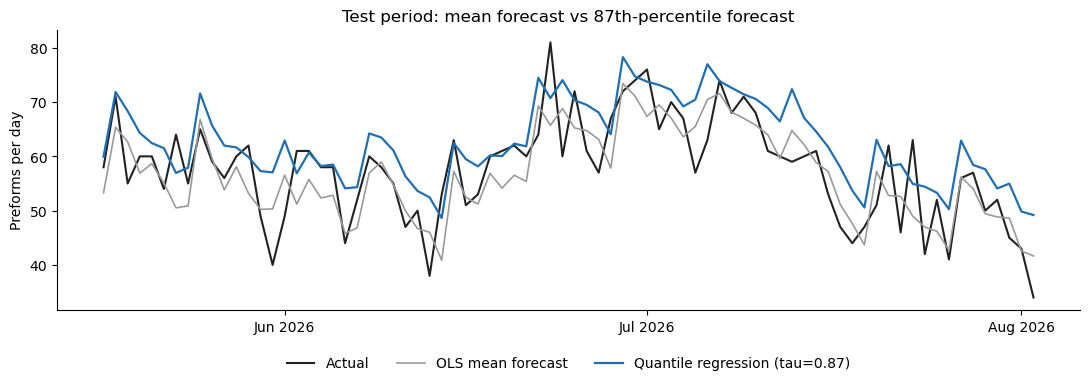

In [26]:
# ===== Quantile models (paste as a new cell after the model cells) =====
# Why: a backorder costs $100/unit/day and holding costs $15/unit/day, so the cost-minimising
# forecast is not the mean but the quantile  tau = 100 / (100 + 15) = 0.87.
# Quantile models predict that quantile directly, instead of "mean forecast + a buffer".
from scipy.stats import norm
from sklearn.linear_model import QuantileRegressor
from sklearn.metrics import mean_pinball_loss

BACK_COST, HOLD_COST = 100, 15
TAU = BACK_COST / (BACK_COST + HOLD_COST)           # 0.8696
y_arr = yte.to_numpy(float)

# --- fit linear and boosted quantile models at the median and at TAU (train block only) ---
q_preds = {}
for tau in [0.50, TAU]:
    qr = QuantileRegressor(quantile=tau, alpha=0.0, solver="highs").fit(Xtr, ytr)
    gq = GradientBoostingRegressor(loss="quantile", alpha=tau, n_estimators=150, max_depth=2,
                                   learning_rate=0.05, subsample=0.8, random_state=SEED).fit(Xtr, ytr)
    q_preds[("Linear quantile regression", tau)] = qr.predict(Xte)
    q_preds[("Gradient boosting (quantile loss)", tau)] = gq.predict(Xte)

# --- benchmark: OLS mean forecast, and OLS mean + a normal-theory buffer (uses TRAIN residuals only) ---
ols_mean = ols.predict(Xte)
train_sd = np.std(ytr.to_numpy(float) - ols.predict(Xtr), ddof=1)
ols_buffer = ols_mean + norm.ppf(TAU) * train_sd


def newsvendor_cost_per_day(y, p):
    """Average daily cost of forecast error: $100 per preform short, $15 per preform over."""
    return BACK_COST * np.mean(np.maximum(y - p, 0)) + HOLD_COST * np.mean(np.maximum(p - y, 0))


def row(name, p, tau):
    return {"Model": name,
            f"Pinball loss (tau={tau:.2f})": mean_pinball_loss(y_arr, p, alpha=tau),
            "Coverage (share actual <= forecast)": np.mean(y_arr <= p),
            "Avg shortfall (preforms/day)": np.mean(np.maximum(y_arr - p, 0)),
            "Avg excess (preforms/day)": np.mean(np.maximum(p - y_arr, 0)),
            "Cost of error ($/day)": newsvendor_cost_per_day(y_arr, p)}


# --- Table 1: targeting the 87th percentile (what the planning model needs) ---
t1 = pd.DataFrame([
    row("OLS mean forecast", ols_mean, TAU),
    row("OLS mean + buffer", ols_buffer, TAU),
    row("Linear quantile regression", q_preds[("Linear quantile regression", TAU)], TAU),
    row("Gradient boosting (quantile loss)", q_preds[("Gradient boosting (quantile loss)", TAU)], TAU),
]).set_index("Model").round(3)
print(f"Target quantile tau = {TAU:.3f}  |  ideal coverage = {TAU:.2f}\n")
display(t1)

# --- Table 2: median forecasts (typical-day accuracy, comparable with the earlier MAE table) ---
med = {"OLS mean forecast": ols_mean,
       "Linear quantile regression (median)": q_preds[("Linear quantile regression", 0.50)],
       "Gradient boosting (median)": q_preds[("Gradient boosting (quantile loss)", 0.50)]}
t2 = pd.DataFrame({k: {"MAE": mean_absolute_error(y_arr, v),
                       "RMSE": np.sqrt(mean_squared_error(y_arr, v)),
                       "Coverage (share actual <= forecast)": np.mean(y_arr <= v)}
                   for k, v in med.items()}).T.round(3)
display(t2)

# --- Figure: actual demand vs mean forecast vs 87th-percentile forecast ---
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(h.date.iloc[te], y_arr, color="#222222", lw=1.5, label="Actual")
ax.plot(h.date.iloc[te], ols_mean, color="#9a9a9a", lw=1.2, label="OLS mean forecast")
ax.plot(h.date.iloc[te], q_preds[("Linear quantile regression", TAU)], color="#1f6fb2", lw=1.6,
        label=f"Quantile regression (tau={TAU:.2f})")
ax.set_ylabel("Preforms per day")
ax.set_title("Test period: mean forecast vs 87th-percentile forecast")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
plt.show()

In [31]:
test_table = pd.DataFrame({
    "date": h.date.iloc[te].dt.date.values,
    "day": h.day_of_week.iloc[te].values,
    "actual": yte.values,
    "naive": preds["Naive (yesterday)"],
    "ols": preds["Linear regression (OLS)"].round(1),
})
test_table["naive_error"] = (test_table["actual"] - test_table["naive"]).round(1)
test_table["ols_error"] = (test_table["actual"] - test_table["ols"]).round(1)
test_table   # all test days in date order

,date,day,actual,naive,ols,naive_error,ols_error
0,2026-05-17,Sun,58,66.0,53.3,-8.0,4.7
1,2026-05-18,Mon,71,58.0,65.4,13.0,5.6
2,2026-05-19,Tue,55,71.0,62.7,-16.0,-7.7
3,2026-05-20,Wed,60,55.0,56.9,5.0,3.1
4,2026-05-21,Thu,60,60.0,58.6,0.0,1.4
...,...,...,...,...,...,...,...
73,2026-07-29,Wed,50,57.0,49.4,-7.0,0.6
74,2026-07-30,Thu,52,50.0,48.8,2.0,3.2
75,2026-07-31,Fri,45,52.0,48.6,-7.0,-3.6
76,2026-08-01,Sat,43,45.0,42.6,-2.0,0.4


### One-day-ahead test metrics

Bias is predicted minus actual, so a negative value means under-forecasting.

In [27]:
res = pd.DataFrame({k: metrics(yte, v) for k, v in preds.items()}).T.round(2)
res

,MAE,RMSE,MAPE_pct,Bias
Naive (yesterday),7.13,8.78,13.00,0.41
Seasonal naive (same weekday last week),7.74,9.62,13.92,0.79
7-day moving average,6.10,7.56,11.29,0.76
Linear regression (OLS),4.72,5.78,8.34,-0.99
Ridge regression (alpha=0.01),4.71,5.78,8.34,-0.99
Gradient boosting (depth 2),5.29,6.63,9.40,-1.46


In [28]:
coef = pd.Series(ols.coef_, index=Xtr.columns).round(3)
coef["intercept"] = round(ols.intercept_, 3)
print("OLS coefficients")
print(coef.to_string())

# paired block bootstrap (7-day blocks) of the MAE gain of OLS over the naive baseline
rng = np.random.default_rng(SEED)
ols_err = np.abs(yte.values - preds["Linear regression (OLS)"])
d = np.abs(yte.values - preds["Naive (yesterday)"]) - ols_err
blocks = [d[i:i + 7] for i in range(0, len(d), 7)]
boot = [np.concatenate([blocks[j] for j in rng.integers(0, len(blocks), len(blocks))]).mean()
        for _ in range(5000)]
print("\nMAE gain of OLS over naive: %.2f, 95%% block-bootstrap CI [%.2f, %.2f]"
      % (d.mean(), *np.percentile(boot, [2.5, 97.5])))

OLS coefficients
lag1               0.231
lag2               0.095
lag7              -0.062
roll7              0.465
large_project      4.215
quote_idx          0.282
quote_idx_lag1    -0.192
dow_Tue           -5.039
dow_Wed           -8.479
dow_Thu           -8.762
dow_Fri          -10.840
dow_Sat          -13.075
dow_Sun          -13.519
intercept         16.069

MAE gain of OLS over naive: 2.41, 95% block-bootstrap CI [1.48, 3.32]


## 4.b Actual vs predicted

Left: the chronological test period. Right: the trained model (not refitted) applied to the confirmed 20-day horizon, **for illustration only**. For planning day *k*, confirmed demand of days 1 to *k-1* is treated as already observed.

In [29]:
c = conf.rename(columns={"confirmed_demand_preforms": Y})[
    ["date", "day_of_week", "large_customer_project", "quote_request_index", Y]]
full = pd.concat([hist[["date", "day_of_week", "large_customer_project",
                        "quote_request_index", Y]], c], ignore_index=True)
ff = build_features(full, Y).iloc[-20:]

conf_pred = pd.DataFrame({
    "planning_day": conf["planning_day"].values,
    "date": conf["date"].dt.date.values,
    "actual_confirmed": conf["confirmed_demand_preforms"].values,
    "naive": ff["lag1"].values,
    "ols": ols.predict(ff[Xtr.columns]).round(1),
})
conf_pred["ols_error"] = (conf_pred["actual_confirmed"] - conf_pred["ols"]).round(1)
display(conf_pred)

print("OLS   (20 days, illustration):", {k: round(float(v), 2) for k, v in
      metrics(conf_pred.actual_confirmed, conf_pred.ols).items()})
print("Naive (20 days, illustration):", {k: round(float(v), 2) for k, v in
      metrics(conf_pred.actual_confirmed, conf_pred.naive).items()})

,planning_day,date,actual_confirmed,naive,ols,ols_error
0,1,2026-08-03,56,34.0,51.2,4.8
1,2,2026-08-04,55,56.0,52.0,3.0
2,3,2026-08-05,54,55.0,48.9,5.1
3,4,2026-08-06,39,54.0,49.0,-10.0
4,5,2026-08-07,56,39.0,51.3,4.7
5,6,2026-08-08,58,56.0,50.7,7.3
6,7,2026-08-09,61,58.0,52.6,8.4
7,8,2026-08-10,72,61.0,66.4,5.6
8,9,2026-08-11,64,72.0,67.1,-3.1
9,10,2026-08-12,62,64.0,63.2,-1.2


OLS   (20 days, illustration): {'MAE': 5.42, 'RMSE': 6.22, 'MAPE_pct': 9.75, 'Bias': -0.71}
Naive (20 days, illustration): {'MAE': 7.85, 'RMSE': 10.04, 'MAPE_pct': 13.93, 'Bias': -1.15}


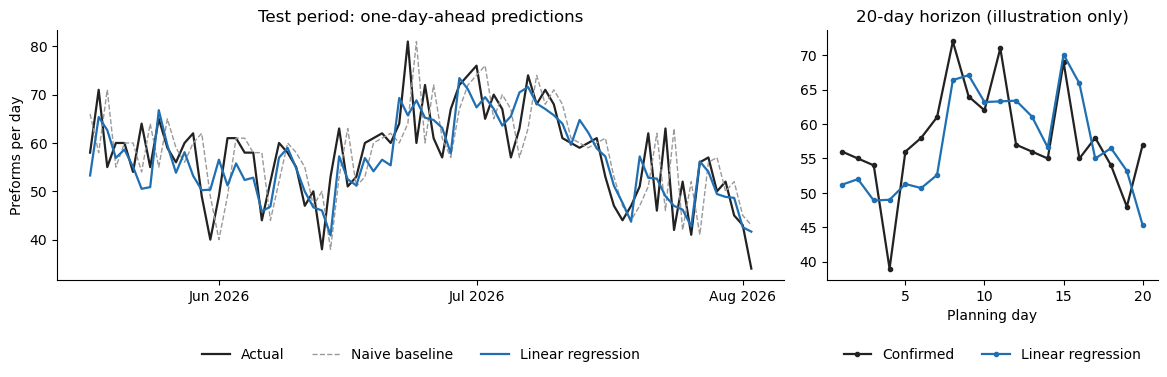

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [2.2, 1]})

ax[0].plot(h.date.iloc[te], yte.values, color="#222222", lw=1.6, label="Actual")
ax[0].plot(h.date.iloc[te], preds["Naive (yesterday)"], color="#9a9a9a", lw=1, ls="--", label="Naive baseline")
ax[0].plot(h.date.iloc[te], preds["Linear regression (OLS)"], color="#1f6fb2", lw=1.6, label="Linear regression")
ax[0].set_title("Test period: one-day-ahead predictions")
ax[0].set_ylabel("Preforms per day")
ax[0].xaxis.set_major_locator(mdates.MonthLocator())
ax[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax[0].legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.22))

ax[1].plot(conf_pred.planning_day, conf_pred.actual_confirmed, color="#222222", lw=1.6, marker="o", ms=3, label="Confirmed")
ax[1].plot(conf_pred.planning_day, conf_pred.ols, color="#1f6fb2", lw=1.6, marker="o", ms=3, label="Linear regression")
ax[1].set_title("20-day horizon (illustration only)")
ax[1].set_xlabel("Planning day")
ax[1].legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.22))

fig.tight_layout()
fig.savefig("task4_actual_vs_predicted.png", dpi=200)
plt.show()